In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = pd.read_csv(r"C:\Users\Admin\OneDrive\画像\Downloads\milknew.csv")

# Remove extra spaces from column names
data.columns = data.columns.str.strip()

print(data.head())
print(data.shape)
print(data.info())

    pH  Temprature  Taste  Odor  Fat  Turbidity  Colour   Grade
0  6.6          35      1     0    1          0     254    high
1  6.6          36      0     1    0          1     253    high
2  8.5          70      1     1    1          1     246     low
3  9.5          34      1     1    0          1     255     low
4  6.6          37      0     0    0          0     255  medium
(1059, 8)
<class 'pandas.DataFrame'>
RangeIndex: 1059 entries, 0 to 1058
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   pH          1059 non-null   float64
 1   Temprature  1059 non-null   int64  
 2   Taste       1059 non-null   int64  
 3   Odor        1059 non-null   int64  
 4   Fat         1059 non-null   int64  
 5   Turbidity   1059 non-null   int64  
 6   Colour      1059 non-null   int64  
 7   Grade       1059 non-null   str    
dtypes: float64(1), int64(6), str(1)
memory usage: 70.8 KB
None


In [3]:
# Check missing values
print(data.isnull().sum())

# Remove missing values
data = data.dropna()

# Check and remove duplicate rows
print("Duplicate rows:", data.duplicated().sum())
data = data.drop_duplicates()

# Check the cleaned dataset
print(data.shape)
print(data["Grade"].value_counts())

pH            0
Temprature    0
Taste         0
Odor          0
Fat           0
Turbidity     0
Colour        0
Grade         0
dtype: int64
Duplicate rows: 976
(83, 8)
Grade
medium    34
low       26
high      23
Name: count, dtype: int64


In [4]:
print(data.describe())
print("Median values:")
print(data.median(numeric_only=True))

              pH  Temprature      Taste       Odor        Fat  Turbidity  \
count  83.000000   83.000000  83.000000  83.000000  83.000000  83.000000   
mean    6.668675   43.698795   0.493976   0.397590   0.602410   0.433735   
std     0.986856    9.379187   0.503003   0.492375   0.492375   0.498602   
min     3.000000   34.000000   0.000000   0.000000   0.000000   0.000000   
25%     6.500000   38.000000   0.000000   0.000000   0.000000   0.000000   
50%     6.600000   41.000000   0.000000   0.000000   1.000000   0.000000   
75%     6.800000   45.000000   1.000000   1.000000   1.000000   1.000000   
max     9.500000   90.000000   1.000000   1.000000   1.000000   1.000000   

           Colour  
count   83.000000  
mean   251.313253  
std      4.577058  
min    240.000000  
25%    247.000000  
50%    255.000000  
75%    255.000000  
max    255.000000  
Median values:
pH              6.6
Temprature     41.0
Taste           0.0
Odor            0.0
Fat             1.0
Turbidity       0.0


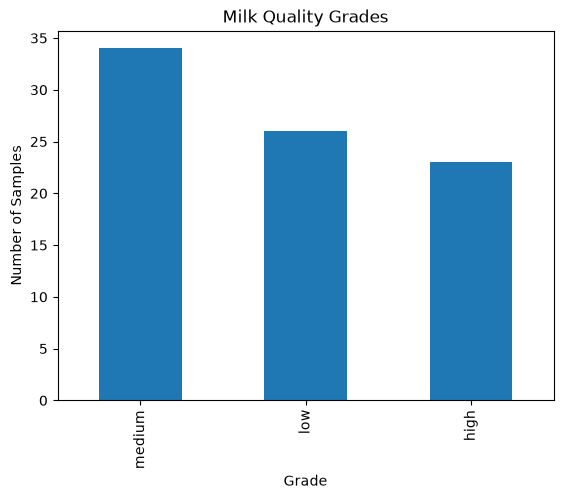

In [5]:
data["Grade"].value_counts().plot(kind="bar")

plt.title("Milk Quality Grades")
plt.xlabel("Grade")
plt.ylabel("Number of Samples")
plt.show()

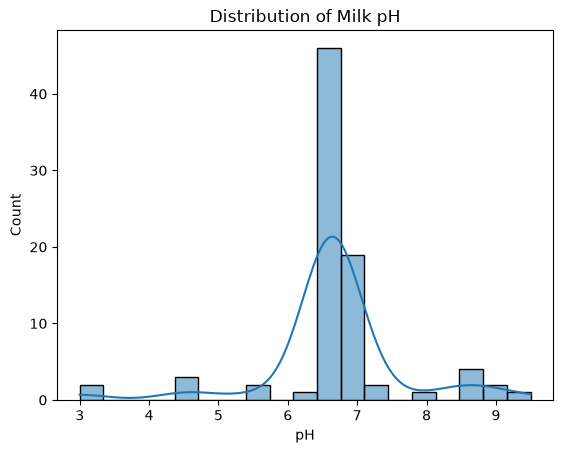

In [6]:
sns.histplot(data=data, x="pH", kde=True)

plt.title("Distribution of Milk pH")
plt.show()

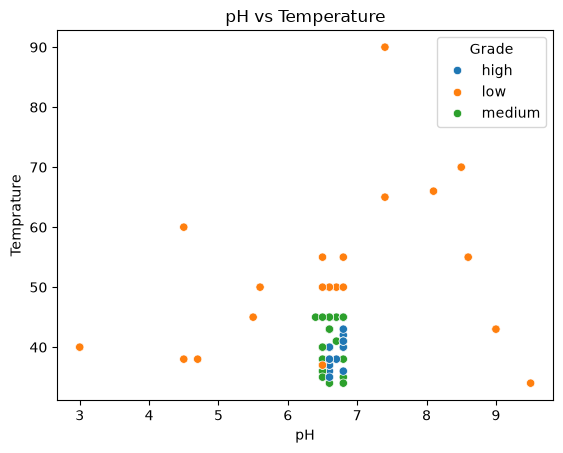

In [7]:
sns.scatterplot(data=data, x="pH", y="Temprature", hue="Grade")

plt.title("pH vs Temperature")
plt.show()

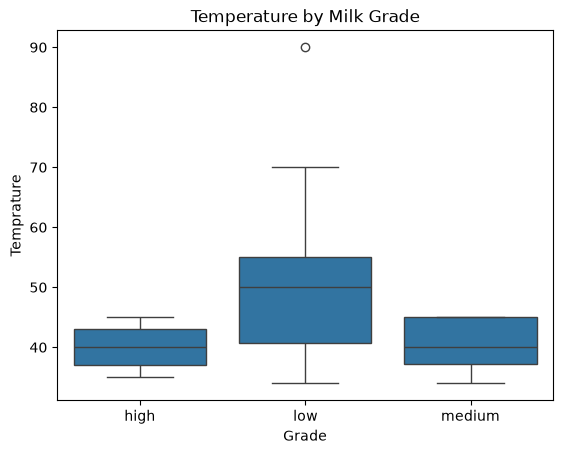

In [8]:
sns.boxplot(data=data, x="Grade", y="Temprature")

plt.title("Temperature by Milk Grade")
plt.show()

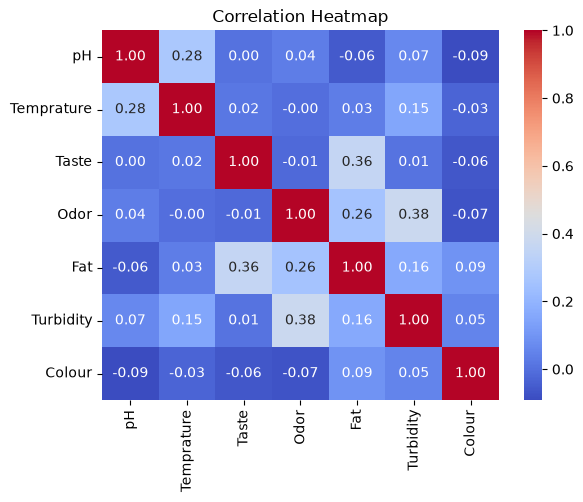

In [9]:
correlation = data.select_dtypes(include=np.number).corr()

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Heatmap")
plt.show()

In [10]:
from scipy.stats import kruskal

high = data[data["Grade"] == "high"]["pH"]
medium = data[data["Grade"] == "medium"]["pH"]
low = data[data["Grade"] == "low"]["pH"]

statistic, p_value = kruskal(high, medium, low)

print("Test statistic:", statistic)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

Test statistic: 1.2727860387294752
P-value: 0.529197791852303
Fail to reject the null hypothesis


In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Input features and target
X = data.drop("Grade", axis=1)
y = data["Grade"]

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Create models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(), LogisticRegression(max_iter=2000)
    ),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42)
}

results = {}

# Train and evaluate each model
for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    results[name] = accuracy

    print("\n", name)
    print("Accuracy:", round(accuracy * 100, 2), "%")
    print(classification_report(y_test, predictions, zero_division=0))

    print("Confusion Matrix:")
    print(confusion_matrix(y_test, predictions))


 Logistic Regression
Accuracy: 58.82 %
              precision    recall  f1-score   support

        high       0.62      1.00      0.77         5
         low       0.25      0.20      0.22         5
      medium       0.80      0.57      0.67         7

    accuracy                           0.59        17
   macro avg       0.56      0.59      0.55        17
weighted avg       0.59      0.59      0.57        17

Confusion Matrix:
[[5 0 0]
 [3 1 1]
 [0 3 4]]

 Decision Tree
Accuracy: 76.47 %
              precision    recall  f1-score   support

        high       0.57      0.80      0.67         5
         low       1.00      0.40      0.57         5
      medium       0.88      1.00      0.93         7

    accuracy                           0.76        17
   macro avg       0.82      0.73      0.72        17
weighted avg       0.82      0.76      0.75        17

Confusion Matrix:
[[4 0 1]
 [3 2 0]
 [0 0 7]]

 Random Forest
Accuracy: 76.47 %
              precision    recall  f1-

                 Model  Accuracy
0  Logistic Regression  0.588235
1        Decision Tree  0.764706
2        Random Forest  0.764706


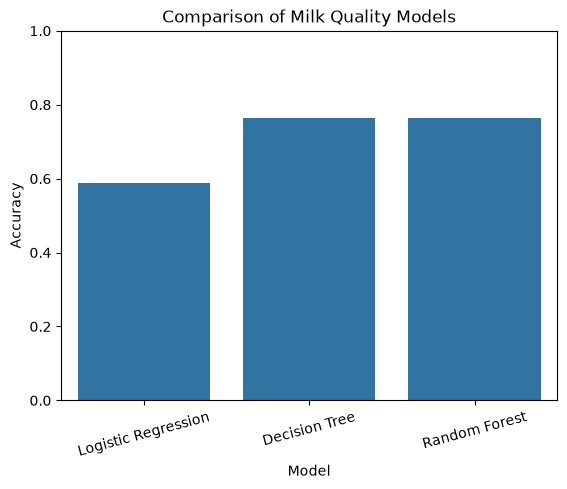

In [12]:
results_df = pd.DataFrame(
    list(results.items()),
    columns=["Model", "Accuracy"]
)

print(results_df)

sns.barplot(data=results_df, x="Model", y="Accuracy")
plt.ylim(0, 1)
plt.title("Comparison of Milk Quality Models")
plt.xticks(rotation=15)
plt.show()

      Feature  Importance
1  Temprature    0.284067
0          pH    0.267596
4         Fat    0.099402
5   Turbidity    0.098578
3        Odor    0.097928
6      Colour    0.076835
2       Taste    0.075594


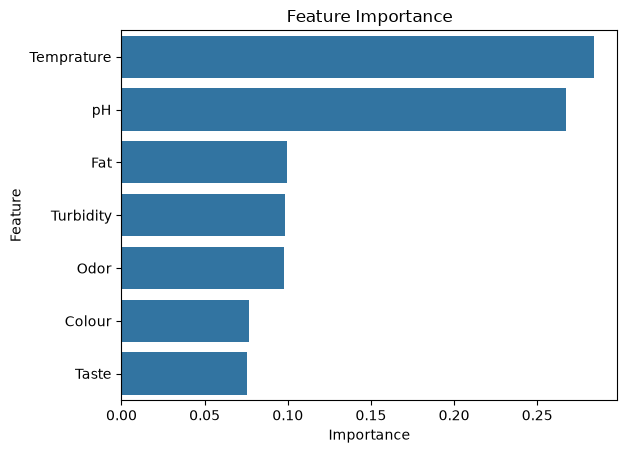

In [13]:
rf_model = models["Random Forest"]

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values("Importance", ascending=False)

print(importance)

sns.barplot(data=importance, x="Importance", y="Feature")
plt.title("Feature Importance")
plt.show()

In [14]:
new_sample = pd.DataFrame([{
    "pH": 6.7,
    "Temprature": 38,
    "Taste": 1,
    "Odor": 0,
    "Fat": 1,
    "Turbidity": 0,
    "Colour": 255
}])

# Use the model with the highest test accuracy
best_model_name = max(results, key=results.get)
best_model = models[best_model_name]

prediction = best_model.predict(new_sample)

print("Best model:", best_model_name)
print("Predicted milk grade:", prediction[0])

Best model: Decision Tree
Predicted milk grade: high


In [15]:
data.to_csv("milknew_cleaned.csv", index=False)

print("Cleaned dataset saved successfully.")

Cleaned dataset saved successfully.
